# Comparison of Classification Models for Credit Card Default Prediction

## Data Preparation

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_validate
from sklearn.model_selection import GridSearchCV
import xgboost as xgb

Dataset Dimension

In [ ]:
data = pd.read_csv('/content/UCI_Credit_Card.csv')
display(data.head())
print(f"Rows: {data.shape[0]}, Columns: {data.shape[1]}\n")

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


Rows: 30000, Columns: 25



Data Structure and Type

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ID                          30000 non-null  int64  
 1   LIMIT_BAL                   30000 non-null  float64
 2   SEX                         30000 non-null  int64  
 3   EDUCATION                   30000 non-null  int64  
 4   MARRIAGE                    30000 non-null  int64  
 5   AGE                         30000 non-null  int64  
 6   PAY_0                       30000 non-null  int64  
 7   PAY_2                       30000 non-null  int64  
 8   PAY_3                       30000 non-null  int64  
 9   PAY_4                       30000 non-null  int64  
 10  PAY_5                       30000 non-null  int64  
 11  PAY_6                       30000 non-null  int64  
 12  BILL_AMT1                   30000 non-null  float64
 13  BILL_AMT2                   300

Target Variable

In [ ]:
print(f"Target Variable: '{'default.payment.next.month'}'")
print(f"Data Type of Target: {data['default.payment.next.month'].dtype}")
print(f"Unique values: {data['default.payment.next.month'].unique()} (0 = Non-default, 1 = Default)")

Target Variable: 'default.payment.next.month'
Data Type of Target: int64
Unique values: [1 0] (0 = Non-default, 1 = Default)


Check Missing Value, Duplicate, Outlier

In [ ]:
print(f"Missing values = {data.isnull().sum().sum()}")

print(f"Duplicate rows = {data.duplicated().sum()}")

print("\nOutliers per column:")
numerical_cols = ['LIMIT_BAL', 'AGE', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']

for col in numerical_cols:
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outlier_count = data[(data[col] < lower_bound) | (data[col] > upper_bound)].shape[0]
    print(f"{col} = {outlier_count}")

Missing values = 0
Duplicate rows = 0

Outliers per column:
LIMIT_BAL = 167
AGE = 272
BILL_AMT1 = 2400
BILL_AMT2 = 2395
BILL_AMT3 = 2469
BILL_AMT4 = 2622
BILL_AMT5 = 2725
BILL_AMT6 = 2693
PAY_AMT1 = 2745
PAY_AMT2 = 2714
PAY_AMT3 = 2598
PAY_AMT4 = 2994
PAY_AMT5 = 2945
PAY_AMT6 = 2958


Those thousand outlier can be a real customer that can be superwealth. Because only a few people that are rich amongst society. So i choose to leave it.

In [ ]:
Q1_age = data['AGE'].quantile(0.25)
Q3_age = data['AGE'].quantile(0.75)
IQR_age = Q3_age - Q1_age
lower_bound_age = Q1_age - 1.5 * IQR_age
upper_bound_age = Q3_age + 1.5 * IQR_age

age_outliers = data[(data['AGE'] < lower_bound_age) | (data['AGE'] > upper_bound_age)]['AGE']

print("=== Age Outlier Analysis ===")
print(f"IQR Bounds for Age: {lower_bound_age} to {upper_bound_age}")
print(f"Total Age Outliers: {len(age_outliers)}")
print(f"Minimum Outlier Age: {age_outliers.min()}")
print(f"Maximum Outlier Age: {age_outliers.max()}")
print("\nUnique outlier age values and their frequencies:")
print(age_outliers.value_counts().sort_index())

=== Age Outlier Analysis ===
IQR Bounds for Age: 8.5 to 60.5
Total Age Outliers: 272
Minimum Outlier Age: 61
Maximum Outlier Age: 79

Unique outlier age values and their frequencies:
AGE
61    56
62    44
63    31
64    31
65    24
66    25
67    16
68     5
69    15
70    10
71     3
72     3
73     4
74     1
75     3
79     1
Name: count, dtype: int64


Age outlier are fine and normal, so we leave it as it is.

Target Variable Distribution

In [ ]:
print(data['default.payment.next.month'].value_counts())
print('\nPercentage:')
print(data['default.payment.next.month'].value_counts(normalize=True) * 100)

default.payment.next.month
0    23364
1     6636
Name: count, dtype: int64

Percentage:
default.payment.next.month
0    77.88
1    22.12
Name: proportion, dtype: float64


Proporsi variabel prediktor masih tergolong bagus, dengan 1 : mengalami default dan 0 : tidak mengalami default.

Train-Test Split

In [ ]:
X = data.drop(columns=['ID', 'default.payment.next.month'])
y = data['default.payment.next.month']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print("y_train class counts:")
print(y_train.value_counts())
print("\ny_test class counts:")
print(y_test.value_counts())

X_train shape: (24000, 23)
X_test shape: (6000, 23)
y_train class counts:
default.payment.next.month
0    18691
1     5309
Name: count, dtype: int64

y_test class counts:
default.payment.next.month
0    4673
1    1327
Name: count, dtype: int64


Check Data Leakage

In [ ]:
train_indices = set(X_train.index)
test_indices = set(X_test.index)
overlap = train_indices.intersection(test_indices)
print(f"Number of overlapping row indices: {len(overlap)}")

merged = pd.concat([X_train, X_test]).duplicated(keep=False)
duplicate_rows_count = merged.sum() - X_train.duplicated(keep=False).sum() - X_test.duplicated(keep=False).sum()
print(f"Number of duplicate feature rows across splits: {max(0, duplicate_rows_count)}")

Number of overlapping row indices: 0
Number of duplicate feature rows across splits: 29


Tidak terjadi data leaakage

## Baseline Model - Logistic Regression

=== 5-Fold Cross Validation (Training Set) ===
Fold Accuracies: [0.80625    0.81583333 0.81395833 0.80895833 0.81125   ]
Mean CV Accuracy: 0.8113 (+/- 0.0068)

Fold F1-scores (Default Class): [0.35326843 0.37746479 0.37333333 0.36275191 0.36197183]
Mean CV F1-score (Default Class): 0.3658 (+/- 0.0173)
Mean CV F1-score (Macro Avg): 0.6274 (+/- 0.0107)

=== Logistic Regression Evaluation ===

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.97      0.89      4673
           1       0.69      0.24      0.36      1327

    accuracy                           0.81      6000
   macro avg       0.75      0.60      0.62      6000
weighted avg       0.79      0.81      0.77      6000



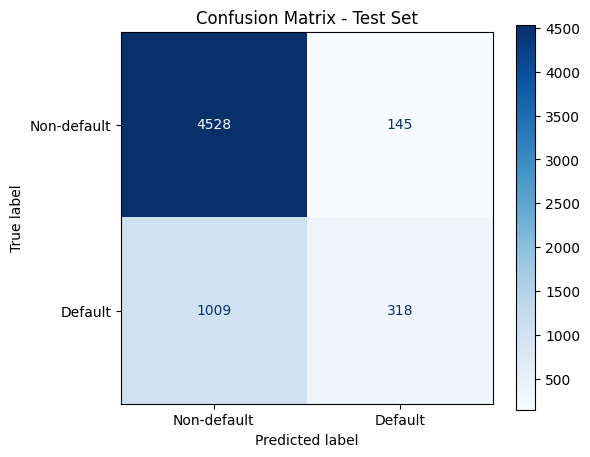

In [ ]:
model_pipeline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42))

cv_scores = cross_val_score(model_pipeline, X_train, y_train, cv=5, scoring='accuracy')
cv_f1_scores = cross_val_score(model_pipeline, X_train, y_train, cv=5, scoring='f1')
cv_f1_macro = cross_val_score(model_pipeline, X_train, y_train, cv=5, scoring='f1_macro')

print("=== 5-Fold Cross Validation (Training Set) ===")
print(f"Fold Accuracies: {cv_scores}")
print(f"Mean CV Accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std() * 2:.4f})")
print(f"\nFold F1-scores (Default Class): {cv_f1_scores}")
print(f"Mean CV F1-score (Default Class): {cv_f1_scores.mean():.4f} (+/- {cv_f1_scores.std() * 2:.4f})")
print(f"Mean CV F1-score (Macro Avg): {cv_f1_macro.mean():.4f} (+/- {cv_f1_macro.std() * 2:.4f})")

model_pipeline.fit(X_train, y_train)

y_pred = model_pipeline.predict(X_test)

print("\n=== Logistic Regression Evaluation ===")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Non-default', 'Default'])
disp.plot(cmap='Blues', values_format='d', ax=ax)
plt.title('Confusion Matrix - Test Set')
plt.show()

## Preprocessing - Logistic Regression

=== 5-Fold Cross Validation (Encoded & Scaled Data) ===
Fold Accuracies: [0.81020833 0.818125   0.81416667 0.810625   0.809375  ]
Mean CV Accuracy: 0.8125 (+/- 0.0065)

Fold F1-scores (Default Class): [0.37129055 0.38736842 0.37535014 0.36918806 0.35879467]
Mean CV F1-score (Default Class): 0.3724 (+/- 0.0185)
Mean CV F1-score (Macro Avg): 0.6311 (+/- 0.0111)

=== Test Set Evaluation (Encoded & Scaled Data) ===

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.97      0.89      4673
           1       0.69      0.24      0.36      1327

    accuracy                           0.81      6000
   macro avg       0.76      0.61      0.62      6000
weighted avg       0.79      0.81      0.77      6000



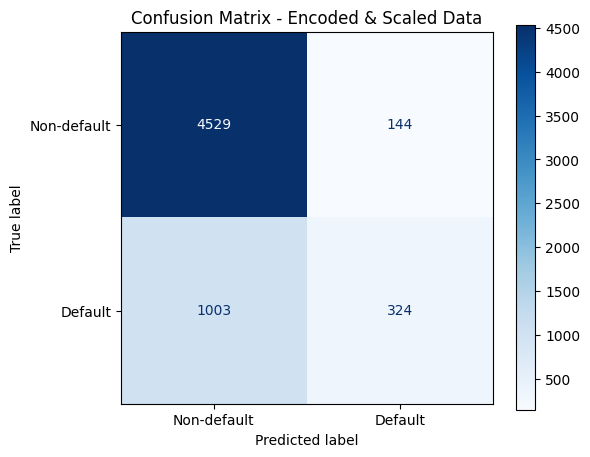

In [ ]:
categorical_cols = ['SEX', 'EDUCATION', 'MARRIAGE']
data_encoded = pd.get_dummies(data, columns=categorical_cols, drop_first=True)

X_prep = data_encoded.drop(columns=['ID', 'default.payment.next.month'])
y_prep = data_encoded['default.payment.next.month']

X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(
    X_prep, y_prep, test_size=0.20, random_state=42, stratify=y_prep
)

prep_pipeline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42))

cv_scores_p = cross_val_score(prep_pipeline, X_train_p, y_train_p, cv=5, scoring='accuracy')
cv_f1_scores_p = cross_val_score(prep_pipeline, X_train_p, y_train_p, cv=5, scoring='f1')
cv_f1_macro_p = cross_val_score(prep_pipeline, X_train_p, y_train_p, cv=5, scoring='f1_macro')

print("=== 5-Fold Cross Validation (Encoded & Scaled Data) ===")
print(f"Fold Accuracies: {cv_scores_p}")
print(f"Mean CV Accuracy: {cv_scores_p.mean():.4f} (+/- {cv_scores_p.std() * 2:.4f})")
print(f"\nFold F1-scores (Default Class): {cv_f1_scores_p}")
print(f"Mean CV F1-score (Default Class): {cv_f1_scores_p.mean():.4f} (+/- {cv_f1_scores_p.std() * 2:.4f})")
print(f"Mean CV F1-score (Macro Avg): {cv_f1_macro_p.mean():.4f} (+/- {cv_f1_macro_p.std() * 2:.4f})")

prep_pipeline.fit(X_train_p, y_train_p)

y_pred_p = prep_pipeline.predict(X_test_p)

print("\n=== Test Set Evaluation (Encoded & Scaled Data) ===")
print("\nClassification Report:")
print(classification_report(y_test_p, y_pred_p))

cm_p = confusion_matrix(y_test_p, y_pred_p)
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_p, display_labels=['Non-default', 'Default'])
disp.plot(cmap='Blues', values_format='d', ax=ax)
plt.title('Confusion Matrix - Encoded & Scaled Data')
plt.show()

I use encoding here so categorical variable change to binary numerical variable that can be processed by the classification model.

All metrics are the same between this model that have been encoded before and model that use original data. Therefore, we can say that there is no significant improvement by doing so.

## Model Comparison

### Decision Tree

=== 5-Fold Cross Validation (Training Set - Decision Tree) ===
Fold Accuracies: [0.724375   0.73166667 0.73416667 0.718125   0.72791667]
Mean CV Accuracy: 0.7273 (+/- 0.0113)

Fold F1-scores (Default Class): [0.40592726 0.40917431 0.42522523 0.38416022 0.39424861]
Mean CV F1-score (Default Class): 0.4037 (+/- 0.0278)
Mean CV F1-score (Macro Avg): 0.6135 (+/- 0.0170)

=== Test Set Evaluation (Decision Tree) ===

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.80      0.81      4673
           1       0.37      0.41      0.39      1327

    accuracy                           0.71      6000
   macro avg       0.60      0.61      0.60      6000
weighted avg       0.73      0.71      0.72      6000



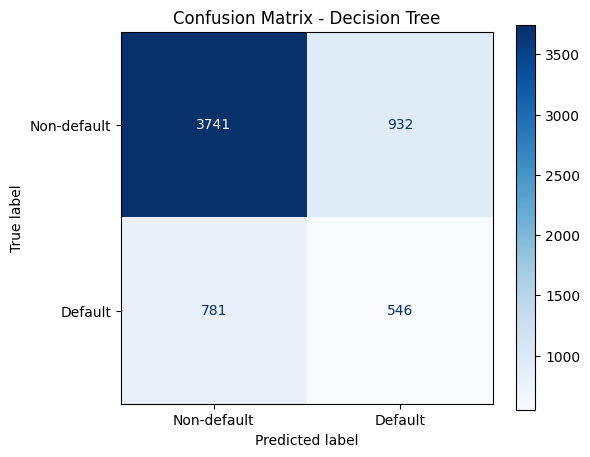

In [ ]:
dt_model = DecisionTreeClassifier(random_state=42)

cv_scores_dt = cross_val_score(dt_model, X_train, y_train, cv=5, scoring='accuracy')
cv_f1_scores_dt = cross_val_score(dt_model, X_train, y_train, cv=5, scoring='f1')
cv_f1_macro_dt = cross_val_score(dt_model, X_train, y_train, cv=5, scoring='f1_macro')

print("=== 5-Fold Cross Validation (Training Set - Decision Tree) ===")
print(f"Fold Accuracies: {cv_scores_dt}")
print(f"Mean CV Accuracy: {cv_scores_dt.mean():.4f} (+/- {cv_scores_dt.std() * 2:.4f})")
print(f"\nFold F1-scores (Default Class): {cv_f1_scores_dt}")
print(f"Mean CV F1-score (Default Class): {cv_f1_scores_dt.mean():.4f} (+/- {cv_f1_scores_dt.std() * 2:.4f})")
print(f"Mean CV F1-score (Macro Avg): {cv_f1_macro_dt.mean():.4f} (+/- {cv_f1_macro_dt.std() * 2:.4f})")

dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)

print("\n=== Test Set Evaluation (Decision Tree) ===")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))

cm_dt = confusion_matrix(y_test, y_pred_dt)
fig, ax = plt.subplots(figsize=(6, 5))
disp_dt = ConfusionMatrixDisplay(confusion_matrix=cm_dt, display_labels=['Non-default', 'Default'])
disp_dt.plot(cmap='Blues', values_format='d', ax=ax)
plt.title('Confusion Matrix - Decision Tree')
plt.show()

## Random Forest

=== Running 5-Fold Cross Validation (Optimized with single pass & parallel jobs) ===
Fold Accuracies: [0.81354167 0.81354167 0.81791667 0.81958333 0.811875  ]
Mean CV Accuracy: 0.8153 (+/- 0.0059)

Fold F1-scores (Default Class): [0.46884273 0.46051838 0.47222222 0.48267622 0.44362292]
Mean CV F1-score (Default Class): 0.4656 (+/- 0.0262)
Mean CV F1-score (Macro Avg): 0.6770 (+/- 0.0144)

=== Test Set Evaluation (Random Forest) ===

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.94      0.89      4673
           1       0.63      0.36      0.46      1327

    accuracy                           0.81      6000
   macro avg       0.74      0.65      0.67      6000
weighted avg       0.79      0.81      0.79      6000



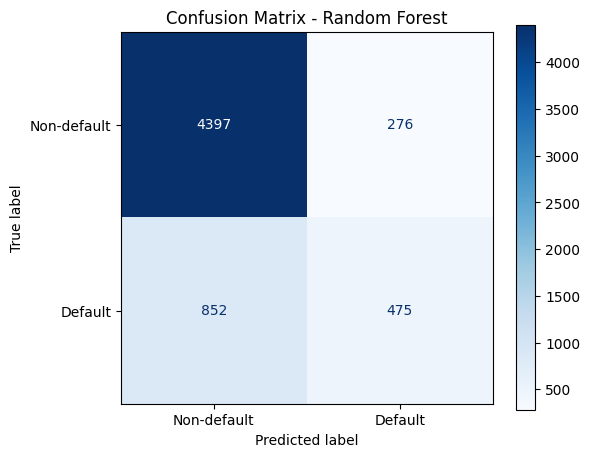

In [ ]:
rf_model = RandomForestClassifier(random_state=42, n_jobs=-1)

print("=== Running 5-Fold Cross Validation (Optimized with single pass & parallel jobs) ===")
scoring = {'accuracy': 'accuracy', 'f1_default': 'f1', 'f1_macro': 'f1_macro'}
cv_results = cross_validate(rf_model, X_train, y_train, cv=5, scoring=scoring, n_jobs=-1)

print(f"Fold Accuracies: {cv_results['test_accuracy']}")
print(f"Mean CV Accuracy: {cv_results['test_accuracy'].mean():.4f} (+/- {cv_results['test_accuracy'].std() * 2:.4f})")
print(f"\nFold F1-scores (Default Class): {cv_results['test_f1_default']}")
print(f"Mean CV F1-score (Default Class): {cv_results['test_f1_default'].mean():.4f} (+/- {cv_results['test_f1_default'].std() * 2:.4f})")
print(f"Mean CV F1-score (Macro Avg): {cv_results['test_f1_macro'].mean():.4f} (+/- {cv_results['test_f1_macro'].std() * 2:.4f})")

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print("\n=== Test Set Evaluation (Random Forest) ===")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

cm_rf = confusion_matrix(y_test, y_pred_rf)
fig, ax = plt.subplots(figsize=(6, 5))
disp_rf = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=['Non-default', 'Default'])
disp_rf.plot(cmap='Blues', values_format='d', ax=ax)
plt.title('Confusion Matrix - Random Forest')
plt.show()

Decision Tree was chosen because it has the highest recall on class 1. This is related to FN, where minimizing false negatives means reducing the number of people who actually default but are predicted as non-default. This is important for banks because identifying people who tend to default can help reduce potential financial losses.

## Hyper Parameter Tuning

=== Starting Hyperparameter Tuning on Decision Tree ===
Fitting 5 folds for each of 90 candidates, totalling 450 fits

Best Hyperparameters found: {'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best Cross-Validation Score (F1-score): 0.4679

=== Test Set Evaluation (Tuned Decision Tree) ===

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.95      0.89      4673
           1       0.66      0.37      0.47      1327

    accuracy                           0.82      6000
   macro avg       0.75      0.66      0.68      6000
weighted avg       0.80      0.82      0.80      6000



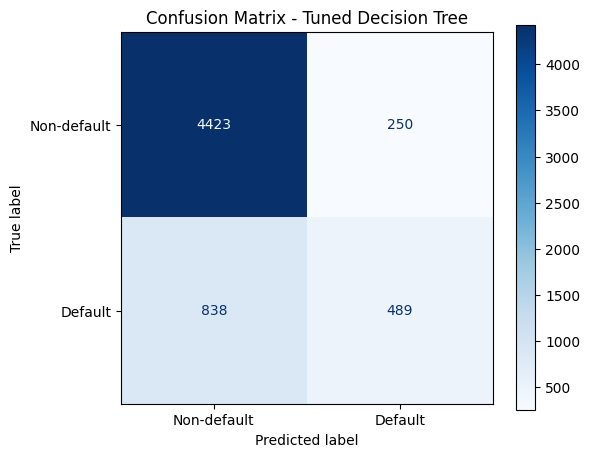

In [ ]:
dt_tuned = DecisionTreeClassifier(random_state=42)

param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [3, 5, 7, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

grid_search_dt = GridSearchCV(
    estimator=dt_tuned,
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

print("=== Starting Hyperparameter Tuning on Decision Tree ===")
grid_search_dt.fit(X_train, y_train)

best_params = grid_search_dt.best_params_
best_dt_model = grid_search_dt.best_estimator_

print(f"\nBest Hyperparameters found: {best_params}")
print(f"Best Cross-Validation Score (F1-score): {grid_search_dt.best_score_:.4f}")

y_pred_tuned_dt = best_dt_model.predict(X_test)

print("\n=== Test Set Evaluation (Tuned Decision Tree) ===")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_tuned_dt))

cm_tuned_dt = confusion_matrix(y_test, y_pred_tuned_dt)
fig, ax = plt.subplots(figsize=(6, 5))
disp_tuned_dt = ConfusionMatrixDisplay(confusion_matrix=cm_tuned_dt, display_labels=['Non-default', 'Default'])
disp_tuned_dt.plot(cmap='Blues', values_format='d', ax=ax)
plt.title('Confusion Matrix - Tuned Decision Tree')
plt.show()

In [ ]:
print("\n=== Test Set Evaluation (Random Forest) ===")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

print("\n=== Test Set Evaluation (Tuned Decision Tree) ===")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_tuned_dt))


=== Test Set Evaluation (Random Forest) ===

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.94      0.89      4673
           1       0.63      0.36      0.46      1327

    accuracy                           0.81      6000
   macro avg       0.74      0.65      0.67      6000
weighted avg       0.79      0.81      0.79      6000


=== Test Set Evaluation (Tuned Decision Tree) ===

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.95      0.89      4673
           1       0.66      0.37      0.47      1327

    accuracy                           0.82      6000
   macro avg       0.75      0.66      0.68      6000
weighted avg       0.80      0.82      0.80      6000



There is a small improvement on the metric we focus onto. Recall on class 1 is increased by 0.01. While other metric also have small improvement and other just the same as the standard decision tree.

## Advanced Model

Mean CV Accuracy: 0.8137 (+/- 0.0037)
Mean CV F1-score (Default Class): 0.4680 (+/- 0.0113)


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [12:50:31] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



=== Test Set Evaluation (Baseline XGBoost) ===

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.94      0.89      4673
           1       0.63      0.36      0.46      1327

    accuracy                           0.81      6000
   macro avg       0.74      0.65      0.67      6000
weighted avg       0.79      0.81      0.79      6000



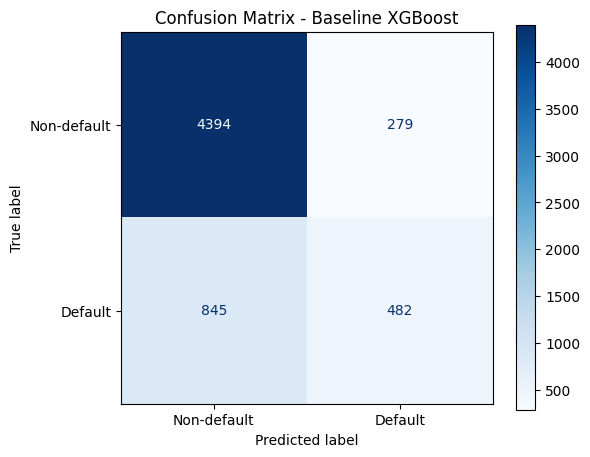

In [ ]:
xgb_model = xgb.XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='logloss')

xgb_cv_accuracy = cross_val_score(xgb_model, X_train_p, y_train_p, cv=5, scoring='accuracy', n_jobs=-1)
xgb_cv_f1 = cross_val_score(xgb_model, X_train_p, y_train_p, cv=5, scoring='f1', n_jobs=-1)

print(f"Mean CV Accuracy: {xgb_cv_accuracy.mean():.4f} (+/- {xgb_cv_accuracy.std() * 2:.4f})")
print(f"Mean CV F1-score (Default Class): {xgb_cv_f1.mean():.4f} (+/- {xgb_cv_f1.std() * 2:.4f})")

xgb_model.fit(X_train_p, y_train_p)

y_pred_xgb = xgb_model.predict(X_test_p)

print("\n=== Test Set Evaluation (Baseline XGBoost) ===")
print("\nClassification Report:")
print(classification_report(y_test_p, y_pred_xgb))

cm_xgb = confusion_matrix(y_test_p, y_pred_xgb)
fig, ax = plt.subplots(figsize=(6, 5))
disp_xgb = ConfusionMatrixDisplay(confusion_matrix=cm_xgb, display_labels=['Non-default', 'Default'])
disp_xgb.plot(cmap='Blues', values_format='d', ax=ax)
plt.title('Confusion Matrix - Baseline XGBoost')
plt.show()

In [ ]:
print("\n=== Test Set Evaluation (Decision Tree) ===")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))

print("\n=== Test Set Evaluation (Baseline XGBoost) ===")
print("\nClassification Report:")
print(classification_report(y_test_p, y_pred_xgb))


=== Test Set Evaluation (Decision Tree) ===

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.80      0.81      4673
           1       0.37      0.41      0.39      1327

    accuracy                           0.71      6000
   macro avg       0.60      0.61      0.60      6000
weighted avg       0.73      0.71      0.72      6000


=== Test Set Evaluation (Baseline XGBoost) ===

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.94      0.89      4673
           1       0.63      0.36      0.46      1327

    accuracy                           0.81      6000
   macro avg       0.74      0.65      0.67      6000
weighted avg       0.79      0.81      0.79      6000



Since the goal is to identify as many potential defaulters as possible, recall is used as the primary evaluation metric. Although Decision Tree has a slightly higher recall for class 1 (0.41) than XGBoost (0.36), XGBoost performs substantially better on the other evaluation metrics, including precision, F1-score, accuracy, and macro F1-score. Therefore, considering the relatively small difference in recall and the better overall performance of XGBoost, XGBoost is selected as the best model for this classification problem.